# Module 20 Initial report and exploratory data analysis

## Submission scope
This self-contained notebook addresses Assignment 20.1: problem statement, data sources and structure, cleaning, exploration, techniques and initial results. It consolidates the completed exploratory and initial-model work for milestone submission. It is not a claim that this notebook was submitted earlier.

**Question:** Can Isolation Forest improve anomaly detection over a statistical rule without creating excessive false alarms when cloud workloads change?

**Business objective:** support human investigation of unusual service measurements while balancing missed detections and alert noise. No production impact or cost saving is measured.

## Data sources and structure
The source is the public Numenta Anomaly Benchmark (NAB). This initial report explores EC2 CPU 5f5533 in depth and compares five series: CPU 5f5533, 24ae8d and 53ea38 from realAWSCloudwatch, plus request latency system failure and ASG CPU misconfiguration from realKnownCause. Each CSV has timestamp and value columns. A separate JSON defines annotation windows used only for evaluation. These are several series from one benchmark, not independent providers.

Run scripts/download_data.py first, then run this notebook from top to bottom. It does not require executing another notebook. Original notebook numbers are retained in the repository as focused technical companions.

## Analysis roadmap
1. Inspect missing values, cadence, duplicates and distributions.
2. Visualize measurements and annotation windows.
3. Demonstrate historical feature construction.
4. Fit and compare the statistical rule and Isolation Forest using a chronological split.
5. Verify results and examine workload shift.
6. Interpret findings and identify next steps.

The exploratory feature demonstration includes current-inclusive trailing summaries; the modeling section independently rebuilds strict preceding-history features. No labels are used for unsupervised fitting. OpenTelemetry was not deployed.

[Module 16 proposal](../milestones/module_16_proposal.md) · [Final README](../README.md)


## Part A Exploratory data analysis

## What this data is — and what it is not

The file `ec2_cpu_utilization_5f5533.csv` is an **Amazon CloudWatch** metric published in the Numenta Anomaly Benchmark (`realAWSCloudwatch`). It is EC2 CPU utilization sampled about every five minutes. NAB also publishes hand-annotated anomaly **windows** in `combined_windows.json`.

This is **not** native OpenTelemetry data. It has no traces, spans, resource attributes, or exemplars. It is **not** a log of verified SaaS customer incidents, and the windows are **not** confirmed root causes. NAB windows are wide intervals drawn around unusual metric behavior so scoring can credit a detector that fires inside the interval. A point inside a window is “inside an annotated window,” not a diagnosed production incident.

We use the series only as a public, time-ordered univariate baseline ; OpenTelemetry ingestion is a proposed future extension and has not been deployed.

## Setup

Paths are resolved from the repository root so the notebook works whether the kernel starts in `notebooks/` or at the repo root. Downloads are written under `data/raw/nab/`. Those files are gitignored.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

sns.set_theme(style="whitegrid")

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

RAW_DIR = REPO_ROOT / "data" / "raw" / "nab"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
CPU_PATH = RAW_DIR / "cpu.csv"
WINDOWS_PATH = RAW_DIR / "anomaly_windows.json"
FEATURES_PATH = PROCESSED_DIR / "nab_cpu_features.csv"

CPU_URL = (
    "https://raw.githubusercontent.com/numenta/NAB/master/data/"
    "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv"
)
WINDOWS_URL = (
    "https://raw.githubusercontent.com/numenta/NAB/master/labels/combined_windows.json"
)
NAB_KEY = "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv"

# 12 samples at a 5-minute cadence is about one hour of history.
ROLLING_WINDOW = 12
LAGS = (1, 2, 3)
FEATURE_COLUMNS = [
    "value",
    "roll_mean_12",
    "roll_std_12",
    "diff_1",
    "lag_1",
    "lag_2",
    "lag_3",
]

print("repo:", REPO_ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__)

repo: C:\Users\rvmkr\OneDrive\Documents\ChatGPT\Homework\capstone_submission
pandas 3.1.1 | numpy 2.5.5


## Obtain the public data
Reuse local benchmark files when present; otherwise download them from NAB. The download script prepares all eight series before notebook execution.

In [2]:
def download(url: str, dest: Path) -> None:
    if dest.exists():
        return
    dest.parent.mkdir(parents=True, exist_ok=True)
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    dest.write_bytes(response.content)
    print(f"saved {dest.relative_to(REPO_ROOT)} ({dest.stat().st_size:,} bytes)")


download(CPU_URL, CPU_PATH)
download(WINDOWS_URL, WINDOWS_PATH)

cpu_head = CPU_PATH.read_text(encoding="utf-8").splitlines()[0]
if cpu_head.strip() != "timestamp,value":
    raise ValueError(f"Unexpected CSV header: {cpu_head!r}")
print("CSV header:", cpu_head)

CSV header: timestamp,value


## Load the metric and the window labels

Timestamps stay timezone-naive, matching the NAB files. An observation is labeled `is_anomaly=True` when its timestamp lies inside any window for `realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv`, including both endpoints. Rows are sorted by time before any feature is computed.

In [3]:
cpu = pd.read_csv(CPU_PATH)
expected_columns = {"timestamp", "value"}
if set(cpu.columns) != expected_columns:
    raise ValueError(f"Unexpected columns: {list(cpu.columns)}")

cpu["timestamp"] = pd.to_datetime(cpu["timestamp"], format="%Y-%m-%d %H:%M:%S")
cpu["value"] = pd.to_numeric(cpu["value"], errors="coerce")
cpu = cpu.sort_values("timestamp").reset_index(drop=True)

if not cpu["timestamp"].is_monotonic_increasing:
    raise ValueError("Timestamps are not strictly chronological after sorting.")
if cpu["timestamp"].duplicated().any():
    raise ValueError("Duplicate timestamps found; refusing to build a single series.")

windows_json = pd.read_json(WINDOWS_PATH, typ="series")
if NAB_KEY not in windows_json.index:
    raise KeyError(f"{NAB_KEY} not found in {WINDOWS_PATH.name}")

windows = []
for start_raw, end_raw in windows_json[NAB_KEY]:
    start = pd.Timestamp(start_raw)
    end = pd.Timestamp(end_raw)
    if end < start:
        raise ValueError(f"Window end before start: {start} .. {end}")
    windows.append((start, end))

cpu["is_anomaly"] = False
for start, end in windows:
    inside = (cpu["timestamp"] >= start) & (cpu["timestamp"] <= end)
    cpu.loc[inside, "is_anomaly"] = True

print(f"rows: {len(cpu):,}")
print(f"range: {cpu['timestamp'].iloc[0]}  ->  {cpu['timestamp'].iloc[-1]}")
print(f"annotated windows for {NAB_KEY}: {len(windows)}")
for start, end in windows:
    n_inside = int(((cpu['timestamp'] >= start) & (cpu['timestamp'] <= end)).sum())
    print(f"  {start}  ->  {end}  ({n_inside} observations)")
print(f"observations inside a window: {int(cpu['is_anomaly'].sum()):,} "
      f"({cpu['is_anomaly'].mean():.1%})")
cpu.head()

rows: 4,032
range: 2014-02-14 14:27:00  ->  2014-02-28 14:22:00
annotated windows for realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv: 2
  2014-02-18 16:02:00  ->  2014-02-19 08:42:00  (201 observations)
  2014-02-24 10:17:00  ->  2014-02-25 02:57:00  (201 observations)
observations inside a window: 402 (10.0%)


,timestamp,value,is_anomaly
0,2014-02-14 14:27:00,51.846,False
1,2014-02-14 14:32:00,44.508,False
2,2014-02-14 14:37:00,41.244,False
3,2014-02-14 14:42:00,48.568,False
4,2014-02-14 14:47:00,46.714,False


## Missing values, cadence, and distribution

CloudWatch’s standard period for this NAB file is five minutes. The checks below report the actual spacing, including any gaps, instead of assuming the file is perfectly regular. Summary statistics describe the CPU values; they are not incident rates.

In [4]:
missing = cpu.isna().sum()
print("Missing values")
print(missing.to_string())
print()

deltas = cpu["timestamp"].diff().dropna()
print("Spacing value counts (top)")
print(deltas.value_counts().head().to_string())
print()
print("median spacing:", deltas.median())
print("min spacing:   ", deltas.min())
print("max spacing:   ", deltas.max())

expected = pd.Timedelta(minutes=5)
gaps = deltas[deltas > expected]
print(f"gaps longer than {expected}: {len(gaps)}")
if len(gaps):
    print(gaps.describe())
if deltas.median() != expected:
    print(f"WARNING: median spacing is {deltas.median()}, not {expected}.")
else:
    print("Median spacing matches the 5-minute CloudWatch period.")

print()
print(cpu["value"].describe().to_string())

Missing values
timestamp     0
value         0
is_anomaly    0

Spacing value counts (top)
timestamp
0 days 00:05:00    4031

median spacing: 0 days 00:05:00
min spacing:    0 days 00:05:00
max spacing:    0 days 00:05:00
gaps longer than 0 days 00:05:00: 0
Median spacing matches the 5-minute CloudWatch period.

count    4032.000000
mean       43.110372
std         4.303565
min        34.766000
25%        39.296000
50%        42.918000
75%        46.006000
max        68.092000


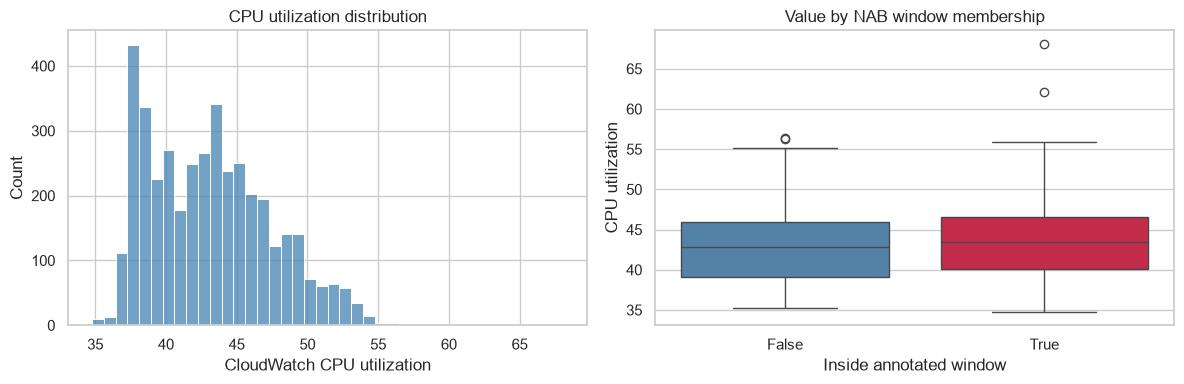

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=cpu, x="value", bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("CPU utilization distribution")
axes[0].set_xlabel("CloudWatch CPU utilization")

sns.boxplot(
    data=cpu,
    x="is_anomaly",
    y="value",
    hue="is_anomaly",
    ax=axes[1],
    palette={False: "steelblue", True: "crimson"},
    legend=False,
)
axes[1].set_title("Value by NAB window membership")
axes[1].set_xlabel("Inside annotated window")
axes[1].set_ylabel("CPU utilization")

fig.tight_layout()
plt.show()

## Time series and annotated windows

Shaded bands are the NAB windows. On the full series, red points mark observations inside those bands. The zoomed panels draw the same interval as a crimson line. The windows are many hours long, so most samples inside them look like ordinary CPU readings; the annotation marks an interval, not every point as a distinct failure.

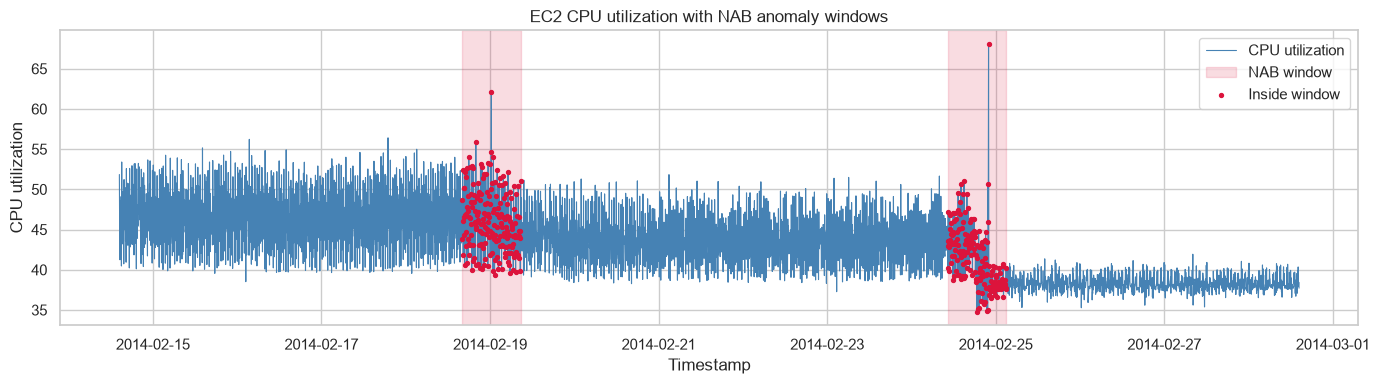

In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(
    cpu["timestamp"],
    cpu["value"],
    color="steelblue",
    linewidth=0.8,
    label="CPU utilization",
)
for i, (start, end) in enumerate(windows):
    ax.axvspan(
        start,
        end,
        color="crimson",
        alpha=0.15,
        label="NAB window" if i == 0 else None,
    )
inside = cpu.loc[cpu["is_anomaly"]]
ax.scatter(
    inside["timestamp"],
    inside["value"],
    s=8,
    color="crimson",
    zorder=3,
    label="Inside window",
)
ax.set_title("EC2 CPU utilization with NAB anomaly windows")
ax.set_xlabel("Timestamp")
ax.set_ylabel("CPU utilization")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

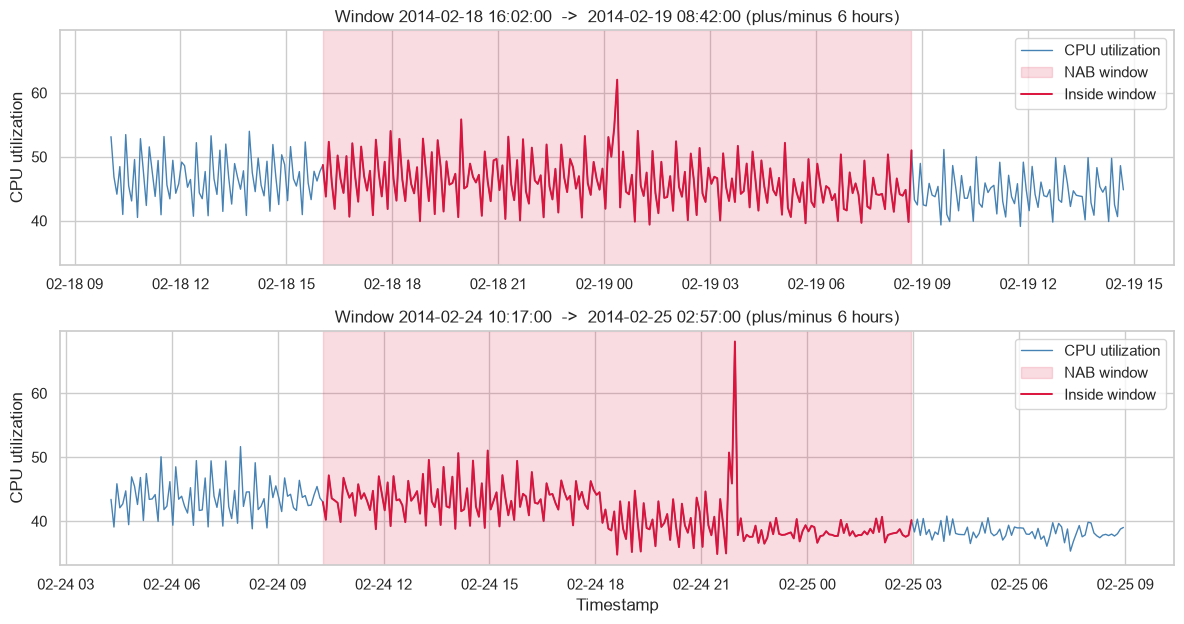

In [7]:
n_windows = len(windows)
fig, axes = plt.subplots(n_windows, 1, figsize=(12, 3.2 * n_windows), sharey=True)
if n_windows == 1:
    axes = [axes]

pad = pd.Timedelta(hours=6)
for ax, (start, end) in zip(axes, windows):
    view = cpu[(cpu["timestamp"] >= start - pad) & (cpu["timestamp"] <= end + pad)]
    ax.plot(view["timestamp"], view["value"], color="steelblue", linewidth=1.0, label="CPU utilization")
    ax.axvspan(start, end, color="crimson", alpha=0.15, label="NAB window")
    flagged = view.loc[view["is_anomaly"]]
    ax.plot(flagged["timestamp"], flagged["value"], color="crimson", linewidth=1.4, label="Inside window")
    ax.legend(loc="upper right")
    ax.set_title(f"Window {start}  ->  {end} (plus/minus 6 hours)")
    ax.set_ylabel("CPU utilization")

axes[-1].set_xlabel("Timestamp")
fig.tight_layout()
plt.show()

## Causal features

Every feature at time *t* uses `value[t]` and earlier values only:

| Column | Definition |
| --- | --- |
| `roll_mean_12` | Mean of the current point and the previous 11 points |
| `roll_std_12` | Sample standard deviation over that same trailing window |
| `diff_1` | `value[t] - value[t-1]` |
| `lag_1`, `lag_2`, `lag_3` | `value[t-1]`, `value[t-2]`, `value[t-3]` |

Pandas rolling windows are right-aligned (`center=False`), so they do not look ahead. The first rows are null until a full window or lag exists. Those rows are kept in the file and should be dropped before modeling. Do not backfill them from later observations.

`is_anomaly` is stored beside the features so a later notebook can score detections. It is excluded from `FEATURE_COLUMNS` and must not be passed to a detector as an input. A chronological split — training only on earlier timestamps — is required when those models are fit. Random splits would leak the level and variance of future traffic into training.

In [8]:
def causal_features(values: pd.Series) -> pd.DataFrame:
    """Trailing features. `values` must already be in chronological order."""
    frame = pd.DataFrame(index=values.index)
    trailing = values.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW, center=False)
    frame["roll_mean_12"] = trailing.mean()
    frame["roll_std_12"] = trailing.std()
    frame["diff_1"] = values.diff(1)
    for lag in LAGS:
        frame[f"lag_{lag}"] = values.shift(lag)
    return frame


features = causal_features(cpu["value"])
model_frame = pd.concat(
    [cpu[["timestamp", "value", "is_anomaly"]], features],
    axis=1,
)

if list(model_frame["timestamp"]) != sorted(model_frame["timestamp"]):
    raise ValueError("Processed frame is not in chronological order.")
if "is_anomaly" in FEATURE_COLUMNS:
    raise ValueError("Anomaly labels must not be model input features.")
missing_features = [name for name in FEATURE_COLUMNS if name not in model_frame.columns]
if missing_features:
    raise ValueError(f"Missing feature columns: {missing_features}")

# A feature at time t must match the feature computed from the prefix ending at t.
prefix = min(200, len(cpu))
prefix_features = causal_features(cpu["value"].iloc[:prefix])
pd.testing.assert_frame_equal(
    features.iloc[:prefix].reset_index(drop=True),
    prefix_features.reset_index(drop=True),
    check_dtype=False,
)
print(f"Causal check passed on the first {prefix} rows.")

print("Nulls introduced by the warm-up (lags and the 12-point window):")
print(model_frame[FEATURE_COLUMNS].isna().sum().to_string())
print()
print("Input features for later models:", FEATURE_COLUMNS)
print("Label column (evaluation only): is_anomaly")
model_frame.head(15)

Causal check passed on the first 200 rows.
Nulls introduced by the warm-up (lags and the 12-point window):
value            0
roll_mean_12    11
roll_std_12     11
diff_1           1
lag_1            1
lag_2            2
lag_3            3

Input features for later models: ['value', 'roll_mean_12', 'roll_std_12', 'diff_1', 'lag_1', 'lag_2', 'lag_3']
Label column (evaluation only): is_anomaly


,timestamp,value,is_anomaly,roll_mean_12,roll_std_12,diff_1,lag_1,lag_2,lag_3
0,2014-02-14 14:27:00,51.846,False,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-02-14 14:32:00,44.508,False,NaN,NaN,-7.338,51.846,NaN,NaN
2,2014-02-14 14:37:00,41.244,False,NaN,NaN,-3.264,44.508,51.846,NaN
3,2014-02-14 14:42:00,48.568,False,NaN,NaN,7.324,41.244,44.508,51.846
4,2014-02-14 14:47:00,46.714,False,NaN,NaN,-1.854,48.568,41.244,44.508
5,2014-02-14 14:52:00,44.986,False,NaN,NaN,-1.728,46.714,48.568,41.244
6,2014-02-14 14:57:00,49.108,False,NaN,NaN,4.122,44.986,46.714,48.568
7,2014-02-14 15:02:00,40.470,False,NaN,NaN,-8.638,49.108,44.986,46.714
8,2014-02-14 15:07:00,53.404,False,NaN,NaN,12.934,40.470,49.108,44.986
9,2014-02-14 15:12:00,45.400,False,NaN,NaN,-8.004,53.404,40.470,49.108


## Save the processed table

`data/processed/nab_cpu_features.csv` keeps the raw value, the evaluation label, and the causal features. The warm-up nulls are preserved on purpose. Downstream notebooks should drop incomplete rows and split by time.

In [9]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
model_frame.to_csv(FEATURES_PATH, index=False)

reloaded = pd.read_csv(FEATURES_PATH, parse_dates=["timestamp"])
if len(reloaded) != len(model_frame):
    raise ValueError(
        f"Reloaded row count {len(reloaded)} != saved row count {len(model_frame)}"
    )
if list(reloaded.columns) != list(model_frame.columns):
    raise ValueError("Reloaded columns do not match the frame that was written.")
if not reloaded["timestamp"].is_monotonic_increasing:
    raise ValueError("Saved timestamps are not chronological.")

print(f"wrote {FEATURES_PATH.relative_to(REPO_ROOT)}")
print(f"rows: {len(reloaded):,}  columns: {list(reloaded.columns)}")
print(f"bytes: {FEATURES_PATH.stat().st_size:,}")
print(
    "rows with a complete feature vector:",
    int(reloaded[FEATURE_COLUMNS].notna().all(axis=1).sum()),
)
reloaded.tail(3)

wrote data\processed\nab_cpu_features.csv
rows: 4,032  columns: ['timestamp', 'value', 'is_anomaly', 'roll_mean_12', 'roll_std_12', 'diff_1', 'lag_1', 'lag_2', 'lag_3']
bytes: 476,747
rows with a complete feature vector: 4021


,timestamp,value,is_anomaly,roll_mean_12,roll_std_12,diff_1,lag_1,lag_2,lag_3
4029,2014-02-28 14:12:00,37.912,False,38.328667,1.185891,-2.440,40.352,38.474,39.878
4030,2014-02-28 14:17:00,38.458,False,38.445500,1.116120,0.546,37.912,40.352,38.474
4031,2014-02-28 14:22:00,37.718,False,38.363000,1.131436,-0.740,38.458,37.912,40.352


## Notes for the next notebooks

- Source: NAB `realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv`, a CloudWatch EC2 CPU series. Not OpenTelemetry, not a SaaS incident log, and not a root-cause dataset.
- Labels: `is_anomaly` is true only inside the published NAB windows. Use it to score detectors. Do not feed it to the model as a feature.
- Order: keep timestamps sorted. Split train, validation, and test by time. Fit any scaler on the training span alone.
- Warm-up: `lag_3` needs 3 prior points and `roll_*_12` needs 12 points. Drop those leading nulls. Do not impute them from the future.
- Features at each row were checked against the same formulas computed on a prefix of the series, which fails if a feature looks ahead.

## Part B Initial modeling and results

The following section rebuilds features directly from the raw files. It runs independently of the exploratory feature output. Reserved validation data were not used to select the original settings; later supervised cross-validation is a separate Module 24 extension in Notebook 06.

In [10]:
%matplotlib inline
# ============================================================
# BERKELEY AI/ML CAPSTONE — DAY 3
# SaaS Observability / AIOps
# Statistical Baseline vs Isolation Forest
# ============================================================

from pathlib import Path
from urllib.request import urlretrieve
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

SEED = 42
np.random.seed(SEED)

## 1. Project directories

In [11]:
root = Path.cwd().resolve()
if not (root / "data").exists():
    root = root.parent

raw_dir = root / "data/raw/nab"
out_dir = root / "data/processed/day3"
raw_dir.mkdir(parents=True, exist_ok=True)
out_dir.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "numenta/NAB/master"
)

# Correct NAB source directories
SERIES = {
    "ec2_cpu_utilization_5f5533":
        "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv",
    "ec2_cpu_utilization_24ae8d":
        "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv",
    "ec2_cpu_utilization_53ea38":
        "realAWSCloudwatch/ec2_cpu_utilization_53ea38.csv",
    "ec2_request_latency_system_failure":
        "realKnownCause/ec2_request_latency_system_failure.csv",
    "cpu_utilization_asg_misconfiguration":
        "realKnownCause/cpu_utilization_asg_misconfiguration.csv"
}

labels_path = raw_dir / "anomaly_windows.json"

if not labels_path.exists():
    urlretrieve(
        BASE_URL + "/labels/combined_windows.json",
        labels_path
    )

with open(labels_path, encoding="utf-8") as f:
    annotations = json.load(f)

## 2. Download and prepare each series

In [12]:
def load_series(name, source):
    path = raw_dir / (name + ".csv")

    # Reuse the original Day 1 dataset if present
    if name == "ec2_cpu_utilization_5f5533":
        original = raw_dir / "cpu.csv"
        if original.exists() and not path.exists():
            path = original

    if not path.exists():
        print("Downloading:", source)
        urlretrieve(
            BASE_URL + "/data/" + source, path
        )

    df = pd.read_csv(path)

    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["value"] = pd.to_numeric(
        df["value"], errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp", "value"])
          .drop_duplicates(subset=["timestamp"])
          .sort_values("timestamp")
          .reset_index(drop=True)
    )

    # Window membership is used for evaluation,
    # never as a model input.
    df["anomaly_label"] = 0

    if source not in annotations:
        raise KeyError(
            f"No NAB annotations found for {source}"
        )

    for start, end in annotations[source]:
        mask = df["timestamp"].between(
            pd.Timestamp(start),
            pd.Timestamp(end)
        )
        df.loc[mask, "anomaly_label"] = 1

    df["series"] = name

    # Strictly historical statistics:
    # shift(1) excludes the current value.
    previous = df["value"].shift(1)

    history = previous.rolling(
        window=12, min_periods=12
    )

    df["past_mean"] = history.mean()
    df["past_std"] = history.std()
    df["lag_1"] = previous
    df["lag_3"] = df["value"].shift(3)
    df["change"] = df["value"] - previous

    df["z_score"] = (
        (df["value"] - df["past_mean"]) /
        df["past_std"].clip(lower=1e-6)
    )

    df = df.replace(
        [np.inf, -np.inf], np.nan
    )

    features = [
        "value", "past_mean", "past_std",
        "lag_1", "lag_3", "change"
    ]

    df = df.dropna(
        subset=features + ["z_score"]
    ).reset_index(drop=True)

    return df, features

## 3. Chronological model development


DATASET: ec2_cpu_utilization_5f5533
Training: 2412 anomalies: 201
Validation: 804 anomalies: 201
Testing: 804 anomalies: 0


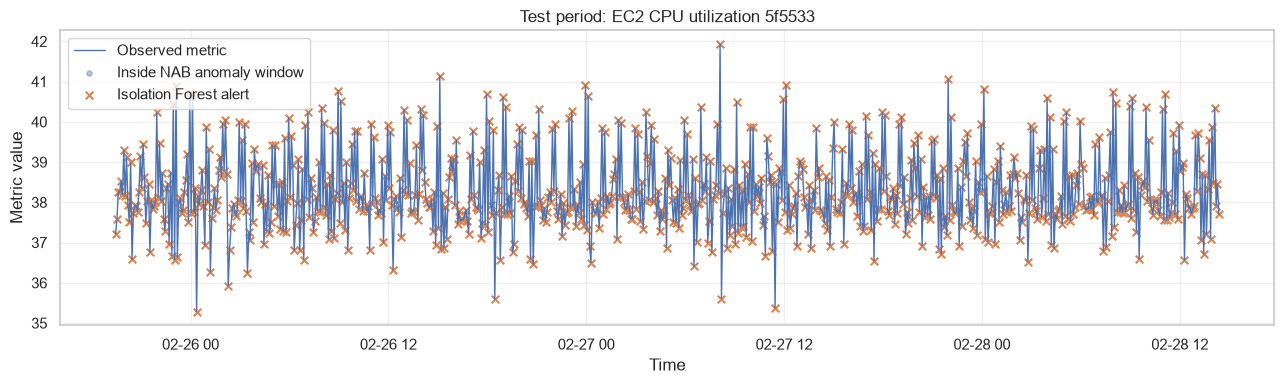


DATASET: ec2_cpu_utilization_24ae8d
Training: 2412 anomalies: 0
Validation: 804 anomalies: 0
Testing: 804 anomalies: 402


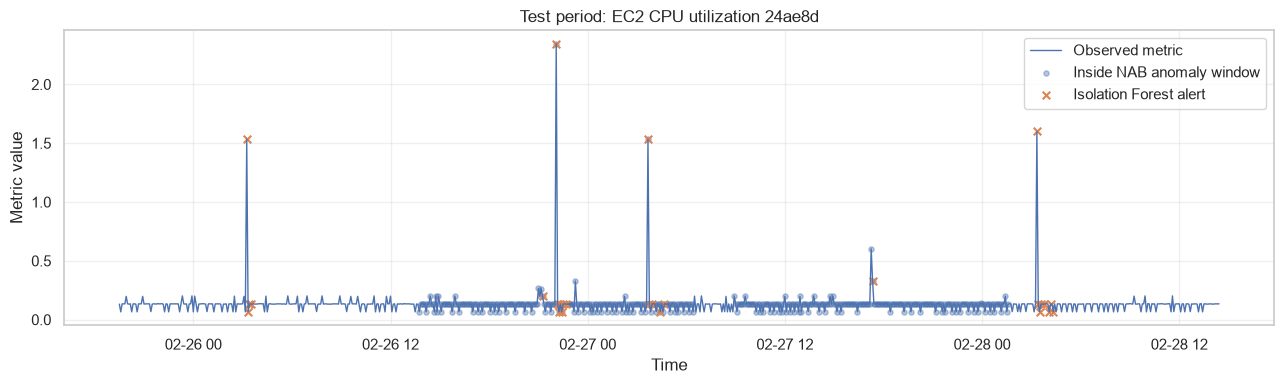


DATASET: ec2_cpu_utilization_53ea38
Training: 2412 anomalies: 201
Validation: 804 anomalies: 201
Testing: 804 anomalies: 0


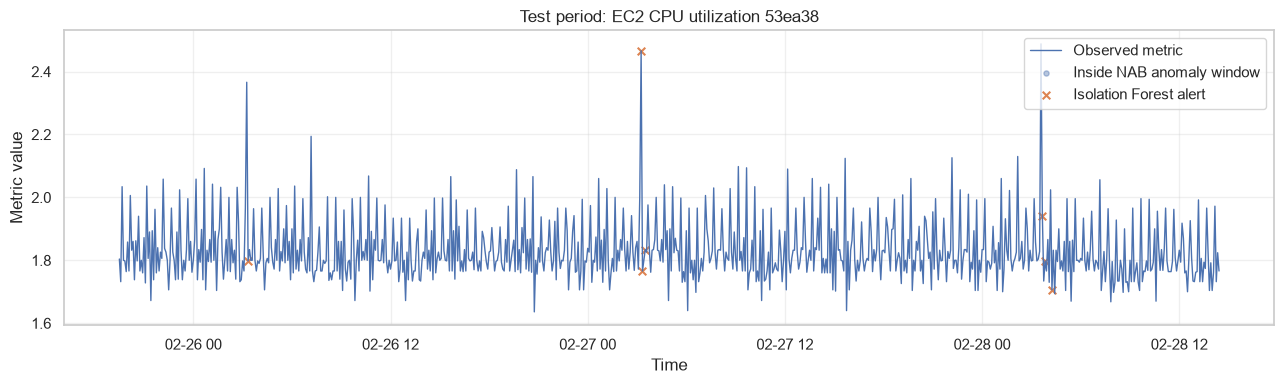


DATASET: ec2_request_latency_system_failure
Training: 2405 anomalies: 135
Validation: 802 anomalies: 0
Testing: 802 anomalies: 211


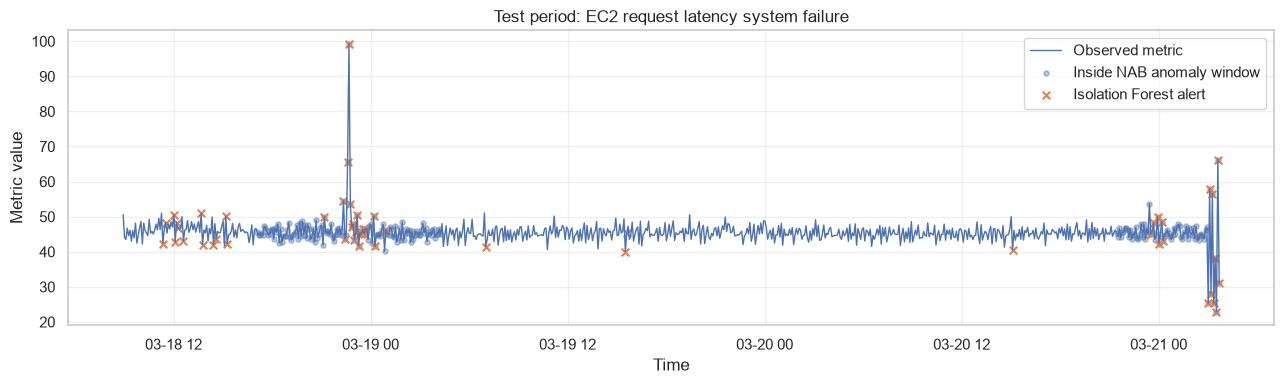


DATASET: cpu_utilization_asg_misconfiguration
Training: 10822 anomalies: 0
Validation: 3608 anomalies: 0
Testing: 3608 anomalies: 1499


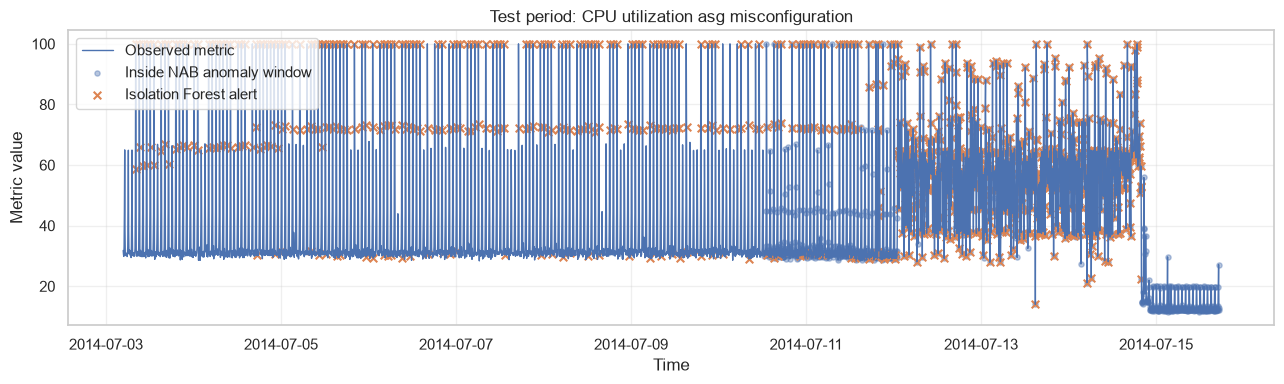

In [13]:
results = []
predictions = []
models = {}

for name, source in SERIES.items():

    print("\n" + "=" * 65)
    print("DATASET:", name)
    print("=" * 65)

    df, feature_cols = load_series(name, source)

    n = len(df)

    train_end = int(n * 0.60)
    val_end = int(n * 0.80)

    train = df.iloc[:train_end].copy()
    validation = df.iloc[train_end:val_end].copy()
    test = df.iloc[val_end:].copy()

    if min(len(train), len(validation), len(test)) == 0:
        print("Insufficient observations; skipping.")
        continue

    print("Training:", len(train),
          "anomalies:", int(train.anomaly_label.sum()))
    print("Validation:", len(validation),
          "anomalies:", int(validation.anomaly_label.sum()))
    print("Testing:", len(test),
          "anomalies:", int(test.anomaly_label.sum()))

    # --------------------------------------------------------
    # Model A: Statistical baseline
    # --------------------------------------------------------

    # Historical z-score, threshold fixed in advance.
    # Do not tune using test labels.
    z_threshold = 3.0

    test["stat_prediction"] = (
        test["z_score"].abs() > z_threshold
    ).astype(int)

    # --------------------------------------------------------
    # Model B: Isolation Forest
    # --------------------------------------------------------

    scaler = RobustScaler()

    X_train = scaler.fit_transform(
        train[feature_cols]
    )

    X_val = scaler.transform(
        validation[feature_cols]
    )

    X_test = scaler.transform(
        test[feature_cols]
    )

    model = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination="auto",
        random_state=SEED,
        n_jobs=-1
    )

    model.fit(X_train)

    # Higher score = more anomalous
    train_scores = -model.score_samples(X_train)
    val_scores = -model.score_samples(X_val)
    test_scores = -model.score_samples(X_test)

    # Fixed 98th percentile of training scores.
    # Training labels are NOT used.
    threshold = float(
        np.quantile(train_scores, 0.98)
    )

    test["if_score"] = test_scores
    test["if_prediction"] = (
        test_scores > threshold
    ).astype(int)

    models[name] = {
        "scaler": scaler,
        "model": model,
        "threshold": threshold
    }

    # --------------------------------------------------------
    # 4. Evaluate held-out test period
    # --------------------------------------------------------

    y_true = test["anomaly_label"].to_numpy()

    for method, column in [
        ("Statistical Z-score", "stat_prediction"),
        ("Isolation Forest", "if_prediction")
    ]:

        y_pred = test[column].to_numpy()

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        # Recall and F1 cannot be interpreted
        # if the test period has no positive labels.
        has_positive = (tp + fn) > 0

        precision = precision_score(
            y_true, y_pred, zero_division=0
        )

        recall = (
            recall_score(y_true, y_pred, zero_division=0)
            if has_positive else np.nan
        )

        f1 = (
            f1_score(y_true, y_pred, zero_division=0)
            if has_positive else np.nan
        )

        false_positive_rate = (
            fp / (fp + tn)
            if (fp + tn) else np.nan
        )

        results.append({
            "series": name,
            "model": method,
            "test_rows": len(test),
            "test_anomalies": int(y_true.sum()),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "false_positive_rate": false_positive_rate,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

    predictions.append(test)

    # --------------------------------------------------------
    # 5. Plot predictions on the held-out test period
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(13, 4))

    ax.plot(
        test["timestamp"], test["value"],
        label="Observed metric", linewidth=1
    )

    actual = test[test["anomaly_label"] == 1]
    detected = test[test["if_prediction"] == 1]

    ax.scatter(
        actual["timestamp"], actual["value"],
        label="Inside NAB anomaly window",
        marker="o", s=14, alpha=0.4
    )

    ax.scatter(
        detected["timestamp"], detected["value"],
        label="Isolation Forest alert",
        marker="x", s=30
    )

    ax.set_title("Test period: " + name.replace("_", " ").replace("ec2", "EC2").replace("cpu", "CPU"))
    ax.set_xlabel("Time")
    ax.set_ylabel("Metric value")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 6. Model comparison

In [14]:
results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("No datasets were successfully evaluated.")

print("\n" + "=" * 65)
print("DAY 3 MODEL COMPARISON")
print("=" * 65)

display(results_df.round(4))

# Aggregate confusion counts across held-out periods.
# These are micro-averaged pointwise metrics.
summary_rows = []

for method, group in results_df.groupby("model"):

    tp = int(group["TP"].sum())
    fp = int(group["FP"].sum())
    fn = int(group["FN"].sum())
    tn = int(group["TN"].sum())

    summary_rows.append({
        "model": method,
        "TP": tp, "FP": fp,
        "FN": fn, "TN": tn,
        "precision": tp / (tp + fp)
            if tp + fp else np.nan,
        "recall": tp / (tp + fn)
            if tp + fn else np.nan,
        "f1": 2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else np.nan,
        "false_positive_rate": fp / (fp + tn)
            if fp + tn else np.nan
    })

summary_df = pd.DataFrame(summary_rows)

print("\nAGGREGATE HELD-OUT PERFORMANCE")
display(summary_df.round(4))


DAY 3 MODEL COMPARISON


,series,model,test_rows,test_anomalies,precision,recall,f1,false_positive_rate,TP,FP,FN,TN
0,ec2_cpu_utilization_5f5533,Statistical Z-score,804,0,0.0000,NaN,NaN,0.0062,0,5,0,799
1,ec2_cpu_utilization_5f5533,Isolation Forest,804,0,0.0000,NaN,NaN,1.0000,0,804,0,0
2,ec2_cpu_utilization_24ae8d,Statistical Z-score,804,402,0.5333,0.0398,0.0741,0.0348,16,14,386,388
3,ec2_cpu_utilization_24ae8d,Isolation Forest,804,402,0.5385,0.0348,0.0654,0.0299,14,12,388,390
4,ec2_cpu_utilization_53ea38,Statistical Z-score,804,0,0.0000,NaN,NaN,0.0149,0,12,0,792
5,ec2_cpu_utilization_53ea38,Isolation Forest,804,0,0.0000,NaN,NaN,0.0087,0,7,0,797
6,ec2_request_latency_system_failure,Statistical Z-score,802,211,0.3333,0.0237,0.0442,0.0169,5,10,206,581
7,ec2_request_latency_system_failure,Isolation Forest,802,211,0.6731,0.1659,0.2662,0.0288,35,17,176,574
8,cpu_utilization_asg_misconfiguration,Statistical Z-score,3608,1499,0.4366,0.0207,0.0395,0.0190,31,40,1468,2069
9,cpu_utilization_asg_misconfiguration,Isolation Forest,3608,1499,0.7475,0.5530,0.6357,0.1328,829,280,670,1829



AGGREGATE HELD-OUT PERFORMANCE


,model,TP,FP,FN,TN,precision,recall,f1,false_positive_rate
0,Isolation Forest,878,1120,1234,3590,0.4394,0.4157,0.4273,0.2378
1,Statistical Z-score,52,81,2060,4629,0.3910,0.0246,0.0463,0.0172


## 7. Save output for the final report

In [15]:
results_df.to_csv(
    out_dir / "per_series_comparison.csv",
    index=False
)

summary_df.to_csv(
    out_dir / "model_comparison.csv",
    index=False
)

pd.concat(predictions, ignore_index=True).to_csv(
    out_dir / "test_predictions.csv",
    index=False
)

## 8. Evaluation limitations

In [16]:
print("\n" + "=" * 65)
print("EVALUATION NOTES")
print("=" * 65)

for name in SERIES:
    sub = results_df[results_df.series == name]

    if not sub.empty and sub.iloc[0].test_anomalies == 0:
        print(
            f"WARNING: {name} has zero labeled test "
            "anomalies. Its recall/F1 are undefined."
        )

print(
    "\nResults are pointwise comparisons, "
    "NOT official NAB benchmark scores."
)
print(
    "NAB anomaly windows represent allowable "
    "temporal detection intervals, not verified "
    "incident duration or precise root-cause timestamps."
)
print(
    "Each time series was modeled independently. "
    "Validation observations were reserved and "
    "test labels were not used for model fitting."
)
print(
    "Thresholds were fixed without inspecting "
    "held-out test labels."
)

print("\nSaved outputs to:", out_dir)
print("\nDAY 3 COMPLETE")


EVALUATION NOTES

Results are pointwise comparisons, NOT official NAB benchmark scores.
NAB anomaly windows represent allowable temporal detection intervals, not verified incident duration or precise root-cause timestamps.
Each time series was modeled independently. Validation observations were reserved and test labels were not used for model fitting.
Thresholds were fixed without inspecting held-out test labels.

Saved outputs to: C:\Users\rvmkr\OneDrive\Documents\ChatGPT\Homework\capstone_submission\data\processed\day3

DAY 3 COMPLETE


## Verify labels, source values, time splits and confusion counts

In [17]:
# Independent verification — Berkeley AIOps Capstone
from pathlib import Path
import pandas as pd
import numpy as np
import json
from sklearn.metrics import confusion_matrix

from pathlib import Path
root = Path.cwd().resolve()
if not (root / "requirements.txt").exists():
    root = root.parent
assert (root / "requirements.txt").exists(), (
    "Project root not found. Open the notebook "
    "from the repository root or notebooks folder."
)

data_dir = root / "data/raw/nab"
result_dir = root / "data/processed/day3"

with open(data_dir / "anomaly_windows.json", encoding="utf-8") as f:
    windows = json.load(f)

sources = {
    "ec2_cpu_utilization_5f5533":
        "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv",
    "ec2_cpu_utilization_24ae8d":
        "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv",
    "ec2_cpu_utilization_53ea38":
        "realAWSCloudwatch/ec2_cpu_utilization_53ea38.csv",
    "ec2_request_latency_system_failure":
        "realKnownCause/ec2_request_latency_system_failure.csv",
    "cpu_utilization_asg_misconfiguration":
        "realKnownCause/cpu_utilization_asg_misconfiguration.csv"
}

pred = pd.read_csv(
    result_dir / "test_predictions.csv",
    parse_dates=["timestamp"]
)

reported = pd.read_csv(
    result_dir / "per_series_comparison.csv"
)

checks = []
recalculated = []

for name, source in sources.items():

    filename = (
        "cpu.csv" if name == "ec2_cpu_utilization_5f5533"
        else name + ".csv"
    )

    raw = pd.read_csv(
        data_dir / filename,
        parse_dates=["timestamp"]
    )

    raw = (
        raw.dropna(subset=["timestamp", "value"])
        .drop_duplicates(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    actual = pred[pred["series"] == name].copy()
    actual = actual.sort_values("timestamp")

    # Rebuild annotations independently
    expected = np.zeros(len(actual), dtype=int)

    for start, end in windows[source]:
        mask = actual["timestamp"].between(
            pd.Timestamp(start),
            pd.Timestamp(end)
        )
        expected[mask.to_numpy()] = 1

    labels_match = np.array_equal(
        expected,
        actual["anomaly_label"].to_numpy()
    )

    # Verify predictions correspond to raw observations
    source_rows = raw.set_index("timestamp")["value"]
    matched_values = actual["timestamp"].map(source_rows)

    values_match = bool(np.allclose(
        matched_values.to_numpy(dtype=float),
        actual["value"].to_numpy(dtype=float),
        equal_nan=False
    ))

    chronological = bool(
        actual["timestamp"].is_monotonic_increasing
        and not actual["timestamp"].duplicated().any()
    )

    # Verify that test data starts after the
    # first 80% of feature-complete observations
    feature_ready = raw.copy()
    feature_ready["previous"] = feature_ready["value"].shift(1)
    feature_ready["past_mean"] = (
        feature_ready["previous"].rolling(12, min_periods=12).mean()
    )
    feature_ready["past_std"] = (
        feature_ready["previous"].rolling(12, min_periods=12).std()
    )
    feature_ready["lag_3"] = feature_ready["value"].shift(3)
    feature_ready["change"] = (
        feature_ready["value"] - feature_ready["previous"]
    )
    feature_ready["z_score"] = (
        (feature_ready["value"] - feature_ready["past_mean"]) /
        feature_ready["past_std"].clip(lower=1e-6)
    )

    feature_ready = feature_ready.replace(
        [np.inf, -np.inf], np.nan
    ).dropna(subset=[
        "value", "previous", "past_mean", "past_std",
        "lag_3", "change", "z_score"
    ]).reset_index(drop=True)

    test_start = int(len(feature_ready) * 0.80)
    expected_test_times = feature_ready.iloc[test_start:]["timestamp"]

    split_matches = np.array_equal(
        actual["timestamp"].to_numpy(),
        expected_test_times.to_numpy()
    )

    checks.append({
        "series": name,
        "labels_match": labels_match,
        "raw_values_match": values_match,
        "chronological": chronological,
        "split_matches": split_matches
    })

    for model_name, col in [
        ("Statistical Z-score", "stat_prediction"),
        ("Isolation Forest", "if_prediction")
    ]:
        y = expected
        p = actual[col].to_numpy(dtype=int)

        tn, fp, fn, tp = confusion_matrix(
            y, p, labels=[0, 1]
        ).ravel()

        saved = reported[
            (reported["series"] == name) &
            (reported["model"] == model_name)
        ]

        counts_match = (
            len(saved) == 1
            and int(saved.iloc[0]["TP"]) == tp
            and int(saved.iloc[0]["FP"]) == fp
            and int(saved.iloc[0]["FN"]) == fn
            and int(saved.iloc[0]["TN"]) == tn
        )

        recalculated.append({
            "series": name,
            "model": model_name,
            "TP": tp, "FP": fp,
            "FN": fn, "TN": tn,
            "saved_counts_match": counts_match
        })

print("DATA INTEGRITY CHECKS")
display(pd.DataFrame(checks))

print("\nINDEPENDENT CONFUSION MATRIX CHECKS")
display(pd.DataFrame(recalculated))

all_data_ok = bool(
    pd.DataFrame(checks).iloc[:, 1:].all().all()
)
all_counts_ok = bool(
    pd.DataFrame(recalculated)["saved_counts_match"].all()
)

print("\nDATA CHECKS:", "PASS" if all_data_ok else "REVIEW")
print("METRIC COUNTS:", "PASS" if all_counts_ok else "REVIEW")

print(
    "\nNote: These checks verify local integrity and "
    "reproducibility, not remote source authenticity "
    "or freedom from model-selection bias."
)

DATA INTEGRITY CHECKS


,series,labels_match,raw_values_match,chronological,split_matches
0,ec2_cpu_utilization_5f5533,True,True,True,True
1,ec2_cpu_utilization_24ae8d,True,True,True,True
2,ec2_cpu_utilization_53ea38,True,True,True,True
3,ec2_request_latency_system_failure,True,True,True,True
4,cpu_utilization_asg_misconfiguration,True,True,True,True



INDEPENDENT CONFUSION MATRIX CHECKS


,series,model,TP,FP,FN,TN,saved_counts_match
0,ec2_cpu_utilization_5f5533,Statistical Z-score,0,5,0,799,True
1,ec2_cpu_utilization_5f5533,Isolation Forest,0,804,0,0,True
2,ec2_cpu_utilization_24ae8d,Statistical Z-score,16,14,386,388,True
3,ec2_cpu_utilization_24ae8d,Isolation Forest,14,12,388,390,True
4,ec2_cpu_utilization_53ea38,Statistical Z-score,0,12,0,792,True
5,ec2_cpu_utilization_53ea38,Isolation Forest,0,7,0,797,True
6,ec2_request_latency_system_failure,Statistical Z-score,5,10,206,581,True
7,ec2_request_latency_system_failure,Isolation Forest,35,17,176,574,True
8,cpu_utilization_asg_misconfiguration,Statistical Z-score,31,40,1468,2069,True
9,cpu_utilization_asg_misconfiguration,Isolation Forest,829,280,670,1829,True



DATA CHECKS: PASS
METRIC COUNTS: PASS

Note: These checks verify local integrity and reproducibility, not remote source authenticity or freedom from model-selection bias.


## Investigate the changing CPU workload

In [18]:
# Day 4 — Diagnose Isolation Forest failure

import pandas as pd
import numpy as np
from pathlib import Path

from pathlib import Path
root = Path.cwd().resolve()
if not (root / "requirements.txt").exists():
    root = root.parent
assert (root / "requirements.txt").exists(), \
    "Project root not found"

pred = pd.read_csv(
    root / "data/processed/day3/test_predictions.csv"
)

series = "ec2_cpu_utilization_5f5533"
test = pred[pred["series"] == series].copy()

print("TEST DATA DISTRIBUTION")
print(test[["value", "past_mean", "past_std",
            "change", "if_score"]].describe())

print("\nISOLATION FOREST ALERT RATE")
print(test["if_prediction"].value_counts())

print("\nMODEL SCORE DISTRIBUTION")
print(test["if_score"].quantile(
    [0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0]
))

# Rebuild the chronological feature table
raw = pd.read_csv(
    root / "data/raw/nab/cpu.csv"
).sort_values("timestamp").reset_index(drop=True)

raw["previous"] = raw["value"].shift(1)
raw["past_mean"] = raw["previous"].rolling(12).mean()
raw["past_std"] = raw["previous"].rolling(12).std()
raw["change"] = raw["value"] - raw["previous"]

raw = raw.dropna().reset_index(drop=True)

cutoff = int(len(raw) * 0.60)

train = raw.iloc[:cutoff]

print("\nTRAIN VS TEST FEATURES")

for col in ["value", "past_mean", "past_std", "change"]:
    print(
        col,
        "| Train mean:", round(train[col].mean(), 4),
        "| Test mean:", round(test[col].mean(), 4),
        "| Train std:", round(train[col].std(), 4),
        "| Test std:", round(test[col].std(), 4)
    )

TEST DATA DISTRIBUTION
            value   past_mean    past_std      change    if_score
count  804.000000  804.000000  804.000000  804.000000  804.000000
mean    38.269776   38.268976    0.985701   -0.001199    0.627089
std      0.976196    0.140276    0.209260    1.545145    0.008600
min     35.278000   37.860667    0.471373   -6.326000    0.592849
25%     37.699500   38.173917    0.839923   -1.135500    0.621983
50%     38.062000   38.260000    0.949544    0.056000    0.630121
75%     38.772500   38.359208    1.122051    1.106500    0.634169
max     41.936000   38.649167    1.627532    4.322000    0.640504

ISOLATION FOREST ALERT RATE
if_prediction
1    804
Name: count, dtype: int64

MODEL SCORE DISTRIBUTION


0.00    0.592849
0.05    0.610097
0.25    0.621983
0.50    0.630121
0.75    0.634169
0.95    0.635572
1.00    0.640504
Name: if_score, dtype: float64

TRAIN VS TEST FEATURES
value | Train mean: 45.1727 | Test mean: 38.2698 | Train std: 3.6723 | Test std: 0.9762
past_mean | Train mean: 45.1803 | Test mean: 38.269 | Train std: 1.4745 | Test std: 0.1403
past_std | Train mean: 3.4484 | Test mean: 0.9857 | Train std: 0.6735 | Test std: 0.2093
change | Train mean: -0.0033 | Test mean: -0.0012 | Train std: 5.9488 | Test std: 1.5451


## Compare score distributions over time

Alert threshold: 0.560734
Train median: 0.464935 alert rate: 2.03 %
Validation median: 0.493763 alert rate: 34.45 %
Test median: 0.630121 alert rate: 100.0 %


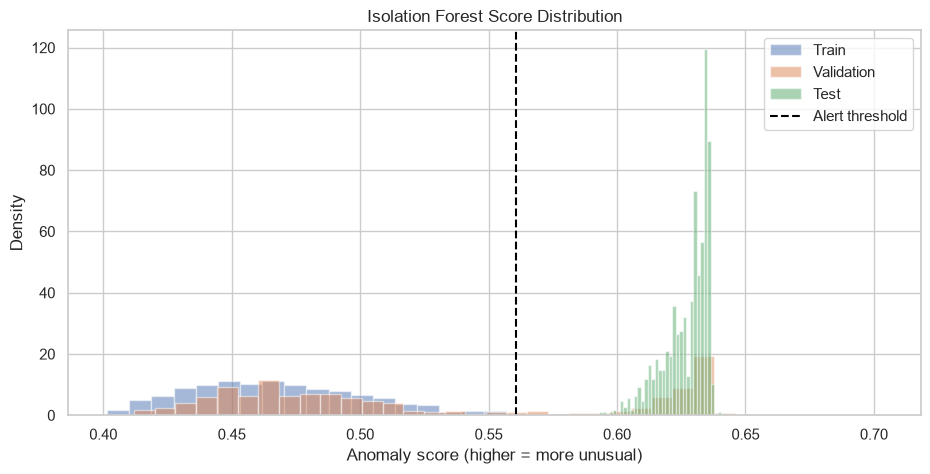

In [19]:
# Day 4: Verify Isolation Forest score drift
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

name = "ec2_cpu_utilization_5f5533"
source = SERIES[name]

df_check, features = load_series(name, source)

n = len(df_check)
train = df_check.iloc[:int(n * 0.60)]
val = df_check.iloc[int(n * 0.60):int(n * 0.80)]
test = df_check.iloc[int(n * 0.80):]

saved = models[name]
scaler = saved["scaler"]
model = saved["model"]
threshold = saved["threshold"]

def anomaly_scores(frame):
    X = scaler.transform(frame[features])
    return -model.score_samples(X)

train_scores = anomaly_scores(train)
val_scores = anomaly_scores(val)
test_scores = anomaly_scores(test)

print("Alert threshold:", round(threshold, 6))

for label, scores in [
    ("Train", train_scores),
    ("Validation", val_scores),
    ("Test", test_scores)
]:
    print(
        label,
        "median:", round(np.median(scores), 6),
        "alert rate:",
        round(100 * np.mean(scores > threshold), 2),
        "%"
    )

plt.figure(figsize=(11, 5))

plt.hist(train_scores, bins=35, alpha=0.5,
         label="Train", density=True)
plt.hist(val_scores, bins=35, alpha=0.5,
         label="Validation", density=True)
plt.hist(test_scores, bins=35, alpha=0.5,
         label="Test", density=True)

plt.axvline(threshold, color="black",
            linestyle="--", label="Alert threshold")

plt.title("Isolation Forest Score Distribution")
plt.xlabel("Anomaly score (higher = more unusual)")
plt.ylabel("Density")
plt.legend()
plt.show()

## Findings and operational next steps

Isolation Forest improves precision and recall for ASG misconfiguration and latency failure, but not consistently across all series. On CPU 5f5533, all 804 normal-labeled test readings are flagged. The observed distribution shift motivates monitoring model behavior and cautious recalibration. It does not identify the cause of the change.

**Action:** retain a statistical reference and require additional event-level evaluation before using these outputs for paging. Recall is undefined when a test period contains no labeled anomalies. The comparison is pointwise, not the official NAB score.

## Initial-report conclusion and progression

Isolation Forest detected 829 of 1,499 ASG window-labeled readings (precision 74.75%, recall 55.30%, F1 0.6357), versus 31 detected by the statistical rule. On latency it detected 35 of 211 versus 5 for the rule. These gains were not universal: CPU 24ae8d recall was slightly lower, while CPU 5f5533 produced 804 false positives out of 804 normal-labeled test readings.

**Interpretation:** model performance depends on workload behavior and the evaluation scenario. Distribution changes are observed, but their operational causes are not established. Window-based labels and correlated observations do not justify causal claims or statistical significance. Some test periods have no anomalies, so recall cannot be estimated there.

**Actions:** retain the statistical comparator, inspect changing distributions, and evaluate candidate updates before operational use. More independent events and unseen workloads are needed. The final report adds periodic-retraining and supervised-validation experiments; their findings do not replace these initial results.

This report fulfills the content scope described for Module 20. Course submission and grading are separate administrative steps.
